In [1]:
import warnings
import joblib
import keras
from keras import layers
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('creditcard.csv')

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [5]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [9]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

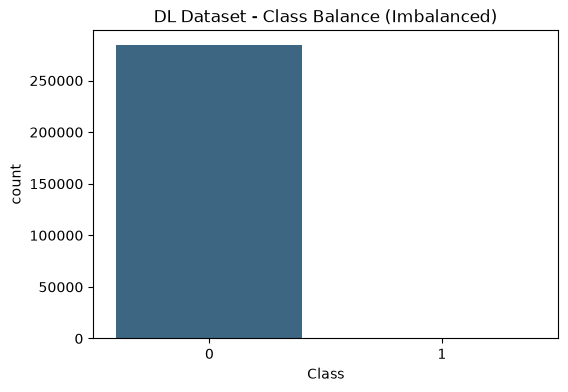

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, palette='viridis')
plt.title('DL Dataset - Class Balance (Imbalanced)')
plt.show()

In [12]:
print(df[['Time', 'Amount']].skew())

Time      -0.035568
Amount    16.977724
dtype: float64


In [13]:
scaler = StandardScaler()
df['NormalizedAmount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))
df['NormalizedTime'] = scaler.fit_transform(df['Time'].values.reshape(-1, 1))
df = df.drop(['Time', 'Amount'], axis=1)

In [14]:
X = df.drop('Class', axis=1).values
y = df['Class'].values

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
input_dim_features = X_train.shape[1]

In [16]:
class_weights_array = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {i: class_weights_array[i] for i in range(len(class_weights_array))}
print(f'\nComputed Class Weights for Imbalance: {class_weights_dict}')


Computed Class Weights for Imbalance: {0: np.float64(0.5008661206149896), 1: np.float64(289.14340101522845)}


In [17]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint = keras.callbacks.ModelCheckpoint('best_checkpoint_model.keras', monitor='val_loss', save_best_only=True)

In [18]:
ann_models = {
    'Shallow ANN': keras.Sequential([
        layers.Dense(32, activation='relu', input_shape=(input_dim_features,)),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ]),
    'Regularized ANN': keras.Sequential([
        layers.Dense(64, activation='relu', input_shape=(input_dim_features,)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ]),
    'Deep Wide ANN': keras.Sequential([
        layers.Dense(128, activation='relu', input_shape=(input_dim_features,)),
        layers.Dropout(0.4),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
}

results = []
trained_models = {}

In [19]:
for name, model in ann_models.items():
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=10,
        batch_size=256,
        class_weight=class_weights_dict,  # Passing computed weights here
        callbacks=[early_stop, checkpoint],
        verbose=0
    )
    
    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob > 0.5).astype(int)
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })
    trained_models[name] = model

In [22]:
print('\n--- Step 7: KerasTuner Optimization ---')
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim_features,)))
    for i in range(hp.Int('num_layers', 1, 2)):
        model.add(layers.Dense(hp.Int(f'units_{i}', 16, 64, step=16), activation='relu'))
        model.add(layers.Dropout(0.3))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Pass overwrite=True to clear out old corrupted tuner cache directories
tuner = kt.RandomSearch(
    build_model, 
    objective='val_loss', 
    max_trials=2, 
    overwrite=True, 
    directory='tuner_dir', 
    project_name='tune'
)

# Add early stopping callback during search so trials complete successfully
tuner_early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=1)

tuner.search(
    X_train, y_train, 
    epochs=5, 
    validation_split=0.1, 
    batch_size=256, 
    class_weight=class_weights_dict, 
    callbacks=[tuner_early_stop],
    verbose=0
)

# Retrieve best hyperparameters and build/train model safely
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.hypermodel.build(best_hps)
best_model.fit(
    X_train, y_train, 
    epochs=5, 
    validation_split=0.1, 
    batch_size=256, 
    class_weight=class_weights_dict, 
    verbose=0
)

y_prob_tuned = best_model.predict(X_test, verbose=0).ravel()
y_pred_tuned = (y_prob_tuned > 0.5).astype(int)

results.append({
    'Model': 'Tuned ANN',
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned, zero_division=0),
    'Recall': recall_score(y_test, y_pred_tuned, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_tuned, zero_division=0)
})
trained_models['Tuned ANN'] = best_model


--- Step 7: KerasTuner Optimization ---


Traceback (most recent call last):
  File "/Users/saurabh/Documents/Capstone_Project_2/myenv/lib/python3.12/site-packages/keras_tuner/src/engine/base_tuner.py", line 274, in _try_run_and_update_trial
    self._run_and_update_trial(trial, *fit_args, **fit_kwargs)
  File "/Users/saurabh/Documents/Capstone_Project_2/myenv/lib/python3.12/site-packages/keras_tuner/src/engine/base_tuner.py", line 239, in _run_and_update_trial
    results = self.run_trial(trial, *fit_args, **fit_kwargs)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/saurabh/Documents/Capstone_Project_2/myenv/lib/python3.12/site-packages/keras_tuner/src/engine/tuner.py", line 309, in run_trial
    self._configure_tensorboard_dir(callbacks, trial, execution)
  File "/Users/saurabh/Documents/Capstone_Project_2/myenv/lib/python3.12/site-packages/keras_tuner/src/engine/tuner.py", line 421, in _configure_tensorboard_dir
    from tensorboard.plugins.hparams import api as hparams_api
ModuleNotFoundError: 

In [24]:
comparison_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
print(comparison_df.to_string(index=False))

          Model  Accuracy  Precision   Recall  F1-Score
Regularized ANN  0.996559   0.318519 0.877551  0.467391
    Shallow ANN  0.988729   0.121170 0.887755  0.213235
  Deep Wide ANN  0.972771   0.055657 0.928571  0.105020
      Tuned ANN  0.971595   0.052415 0.908163  0.099109


In [26]:
best_dl_name = comparison_df.iloc[0]['Model']
trained_models[best_dl_name].save('best_dl_model.keras')
joblib.dump(scaler, 'scaler_dl.pkl')

['scaler_dl.pkl']